# Universidad de Buenos Aires
# Aprendizaje Profundo - TP2
# Cohorte 26 - 4to bimestre 2026

## **Alumno 1:** Denis Zhbankov  
## **Alumno 2:** Elián Pinzás  
## **Alumno 3:** Gonzalo Rodriguez

# CASO: Adult Census Income

El objetivo del trabajo es construir un modelo de clasificación binaria que, a partir de los datos censales de diferentes hogares, determine si un individuo pertenece al grupo de mayores o de menores ingresos. Para ello, se empleará un conjunto de variables demográficas, laborales y socioeconómicas que describen las características de cada persona. El estudio debe incluir el análisis exploratorio del dataset, la selección y justificación de las transformaciones más adecuadas para cada variable, la construcción de modelos basados tanto en técnicas de codificación tradicionales como también en representaciones avanzadas mediante embeddings, y la comparación final del desempeño obtenido por cada enfoque.

**Para este caso de estudio, consideraremos como variable de alta cardinalidad a las que tengan 10 o más valores únicos.**


**Encontrarán el dataset en el siguiente enlace de drive: [link](https://drive.google.com/drive/folders/1S-usUXkJP6OdzUS0zdC5CW-XqegiXzln?usp=sharing)**

Está compuesto por los siguientes features:
- **age**: Edad del individuo expresada en años.

- **workclass**: Tipo de empleador o relación laboral del individuo. Describe si trabaja en el sector privado, gobierno estatal, local, federal, por cuenta propia, sin remuneración, etc.

- **education**: Nivel educativo alcanzado. Incluye categorías como secundaria completada, licenciatura, maestría, doctorado, etc.

- **marital-status**: Estado civil (casado, nunca casado, divorciado, viudo, etc.).

- **occupation**: Tipo de ocupación o área laboral, donde se incluye ventas, servicios de protección, técnicos, gerencia ejecutiva, fuerzas armadas, etc.

- **relationship**: Relación del individuo con el jefe del hogar como esposo, esposa, hijo propio, pariente, no familiar, etc.

- **race**: Autoidentificación racial como blanca, negra, indígena, asiática, isleños del Pacífico, entre otras.

- **sex**: Sexo biológico del individuo (masculino o femenino).

- **capital-gain**: Ingresos obtenidos por ganancia de capital (por ejemplo, venta de acciones o propiedades).

- **capital-loss**: Pérdidas declaradas por capital.

- **hours-per-week**: Cantidad de horas trabajadas por semana.

- **skill-profile**: Habilidad principal o conocmiento técnico adquirido que podría aplicar en el trabajo.

- **native-country**: País de nacimiento del individuo. Incluye Estados Unidos y una lista amplia de países del mundo.

- **income (target)**: Clasificación binaria que indica si el ingreso anual del individuo es menor o igual a 50K o mayor a 50K.

## a) Análisis exploratorio de los datasets (2 puntos)

- Realizar un EDA apoyado en gráficas adecuadas y coherentes para el caso de estudio.
- Analizar detalladamente los valores únicos de cada variable categórica e identificar su nivel de cardinalidad.
- Justificar de manera detallada el tipo de transformación que se le asignará a cada variable, en especial a las categóricas. **Dependiendo de su cardinalidad, su contexto y/o lógica interna de orden**, podrán transformarse mediante label/ordinal encoding, one-hot encoding o mediante una capa de embeddings dentro del modelo.
- No es necesario aplicar la misma transformación para todas las variables categóricas. El dataset puede (y debe) incluir diferentes tipos de transformaciones según las características de cada variable.
- Redactar explícitamente la decisión final adoptada para cada variable y su justificación correspondiente.

In [ ]:
import pandas as pd
import gdown

In [ ]:
!gdown 11yt9E0iNnE6mNuaqqHpkAmaKNfUxz8TY -O adult_train.csv
df_train = pd.read_csv('adult_train.csv')
df_train.head()

Downloading...
From: https://drive.google.com/uc?id=11yt9E0iNnE6mNuaqqHpkAmaKNfUxz8TY
To: /content/adult_train.csv
100% 3.77M/3.77M [00:00<00:00, 269MB/s]


,age,workclass,education,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,skill-profile,native-country,income
0,39,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,manufacturing_assembly,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,accounting_bookkeeping,United-States,<=50K
2,38,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,agriculture_field_work,United-States,<=50K
3,53,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,office_data_entry_basic,United-States,<=50K
4,28,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,tech_programming_advanced,Cuba,<=50K


In [ ]:
!gdown 18M9gI8IlZlDOlN69XIz46ATet4caQVOZ -O adult_val.csv
df_val = pd.read_csv('adult_val.csv')
df_val.head()

Downloading...
From: https://drive.google.com/uc?id=18M9gI8IlZlDOlN69XIz46ATet4caQVOZ
To: /content/adult_val.csv
100% 1.89M/1.89M [00:00<00:00, 179MB/s]


,age,workclass,education,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,skill-profile,native-country,income
0,25,Private,11th,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,logistics_warehouse_basic,United-States,<=50K
1,38,Private,HS-grad,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,security_patrol_basic,United-States,<=50K
2,28,Local-gov,Assoc-acdm,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,trade_cnc_operation,United-States,>50K
3,44,Private,Some-college,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,transport_commercial_driving,United-States,>50K
4,34,Private,10th,Never-married,Other-service,Not-in-family,White,Male,0,0,30,personal_care_assistance,United-States,<=50K


In [ ]:
print("--- Estructura de Train ---")
df_train.info()

print("\n--- Estructura de Validation ---")
df_val.info()

print("\nForma de Train:", df_train.shape)
print("Forma de Validation:", df_val.shape)

--- Estructura de Train ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30162 entries, 0 to 30161
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             30162 non-null  int64 
 1   workclass       30162 non-null  object
 2   education       30162 non-null  object
 3   marital-status  30162 non-null  object
 4   occupation      30162 non-null  object
 5   relationship    30162 non-null  object
 6   race            30162 non-null  object
 7   sex             30162 non-null  object
 8   capital-gain    30162 non-null  int64 
 9   capital-loss    30162 non-null  int64 
 10  hours-per-week  30162 non-null  int64 
 11  skill-profile   30162 non-null  object
 12  native-country  30162 non-null  object
 13  income          30162 non-null  object
dtypes: int64(4), object(10)
memory usage: 3.2+ MB

--- Estructura de Validation ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15060 entries, 0 to 1505

In [ ]:
# Valores nulos
print("--- Nulos explícitos en Train ---")
print(df_train.isnull().sum()[df_train.isnull().sum() > 0])

print("\n--- Nulos explícitos en Validation ---")
print(df_val.isnull().sum()[df_val.isnull().sum() > 0])

--- Nulos explícitos en Train ---
Series([], dtype: int64)

--- Nulos explícitos en Validation ---
Series([], dtype: int64)


No se encuentran valores nulos en ninguno de los dos datasets

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

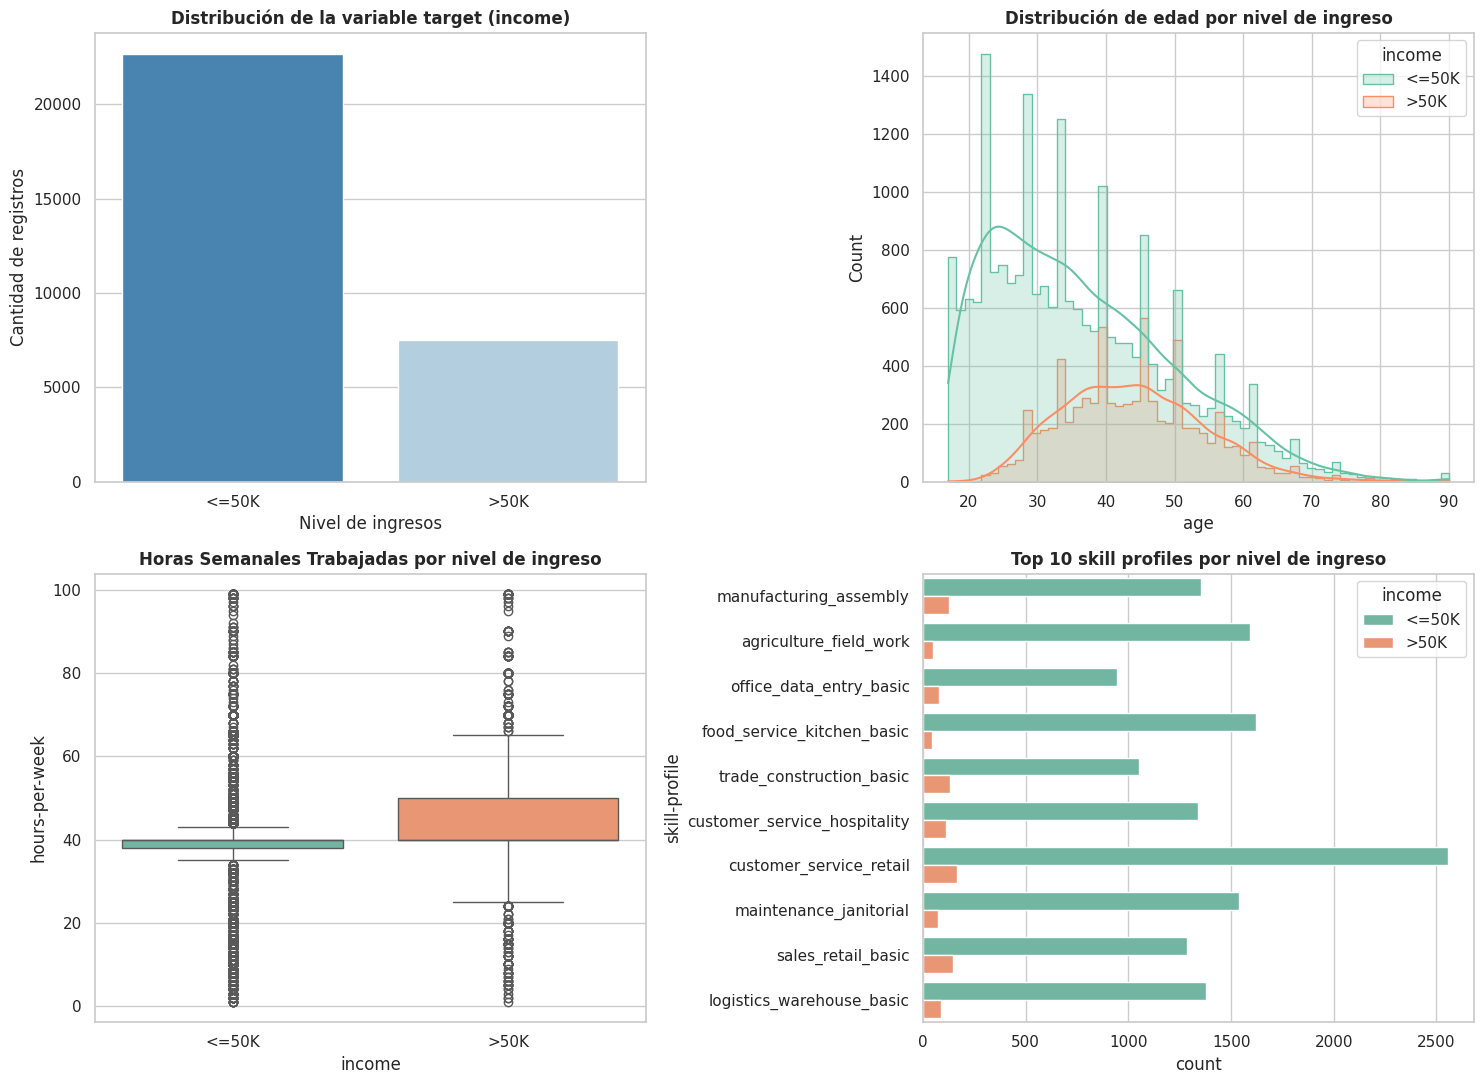

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Desbalance de la variable objetivo
sns.countplot(data=df_train, x='income', hue='income', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Distribución de la variable target (income)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Nivel de ingresos')
axes[0, 0].set_ylabel('Cantidad de registros')

# 2. Distribución de edad según ingresos
sns.histplot(data=df_train, x='age', hue='income', kde=True, ax=axes[0, 1], palette='Set2', element="step")
axes[0, 1].set_title('Distribución de edad por nivel de ingreso', fontsize=12, fontweight='bold')

# 3. Horas trabajadas según ingresos
sns.boxplot(data=df_train, x='income', y='hours-per-week', hue='income', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Horas Semanales Trabajadas por nivel de ingreso', fontsize=12, fontweight='bold')

# 4. Top 10 habilidades técnicas
top_skills = df_train['skill-profile'].value_counts().head(10).index
sns.countplot(data=df_train[df_train['skill-profile'].isin(top_skills)], y='skill-profile', hue='income', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Top 10 skill profiles por nivel de ingreso', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

**Análisis de cardinalidad**

In [ ]:
print("Valores únicos por variable categórica:")
cat_cols = df_train.select_dtypes(include='object').drop(columns=['income']).columns
for col in cat_cols:
    print(f"- {col}: {df_train[col].nunique()} valores únicos")

Valores únicos por variable categórica:
- workclass: 7 valores únicos
- education: 16 valores únicos
- marital-status: 7 valores únicos
- occupation: 14 valores únicos
- relationship: 6 valores únicos
- race: 5 valores únicos
- sex: 2 valores únicos
- skill-profile: 80 valores únicos
- native-country: 41 valores únicos


**Observaciones**:
- Desbalance de clases (**income**): se observa, grosso modo, que el 75% de los datos pertenecen a menor o igual a 50K y el 25% a más de 50K.
- Relación edad/ingresos (**age**): las personas con ingresos mayores a 50K tienden a concentrarse entre los 35 y 55 años, mientras que la población joven (menos de 30 años) se encuentra mayoritariamente en ingresos menores o iguales a 50K.
- Horas trabajadas (**hours-per-week**): quienes ganan más de 50K trabajan en mediana más de 40 horas semanales, mayor cantidad en relación al grupo de menor o igual a 50K.
- Cardinalidad: las variables categóricas education, occupation, skill-profile y native-country poseen alta cardinalidad, es decir, poseen más de 10 valores diferentes, siendo skill-profile la de mayor cardinalidad (80 valores únicos).

**Transformaciones a realizar**  
Para realizar una transformación adecuada de los datos a fin de que el modelo funcione correctamente se realizarán las siguientes transformaciones:
- **Variables categóricas de baja cardinalidad sin orden (sex, race, relationship, marital-status, workclass)**: se realizará una transformación ***one-hot encoding***. La razón es que son variables que tienen pocas categorías (menos de 10). Al codificarse como vectores disjuntos se evita imponer un orden numérico artificial
- **Variable categórica ordinal (education)**: se realizará un ***ordinal encoding***. En este caso existe un orden ya que cada nivel representa un grado mayor de instrucción. Le permite al modelo comprender el nivel académico.
- **Variables categóricas de alta cardinalidad (occupation, native-country, skill-profile)**: se realizará una transformación en ***embeddings***. Si se usara otro método (por ejemplo: one-hot encoding) se incrementaría la cantidad de parámetros del modelo en forma desmedida. Una capa de embeddings proyecta estas categorías en espacios de menor dimensión. Además se enriquece semánticamente al modelo.
- **Variables numéricas continuas (age, capital-gain, capital-loss, hours-per-week)**: se transformarán usando un standard scaler. Las redes neuronales son sensibles a las diferencias de escala en las entradas continuas. Escalar las variables a media cero y varianza unitaria estabilizará los cálculos, favoreciendo el modelo.

**Resumen:**
* **age**: standard scaler
* **capital-gain**: standard scaler
* **capital-loss**: standard scaler
* **hours-per-week**: standard scaler
* **sex**: One-Hot Encoding
* **race**:  One-Hot Encoding
* **relationship**:  One-Hot Encoding
* **marital-status**:  One-Hot Encoding
* **workclass**: One-Hot Encoding
* **education**: Ordinal Encoding
* **occupation**: Embeddings
* **native-country**: Embeddings
* **skill-profile**: Embeddings

## b) Diseño y entrenamiento de un modelo con embeddings (3 puntos)

- Implementar las transformaciones definidas en el punto anterior e incorporarlas al flujo de entrenamiento.
- El modelo debe incluir, como mínimo, una capa de embedding para representar alguna de las variables categóricas.
- La elección de la dimensión del o los embeddings queda a criterio del estudiante, pero debe estar correctamente fundamentada. Recuerden que no es obligatorio que todos los embeddings tengan la misma dimensión.
- La configuración arquitectónica (número de capas, neuronas por capa, función de activación) es de libre elección.
- Incluir dropout en las capas ocultas de la red.
- Utilizar Adam o alguna de sus variantes como optimizador.
- Seleccionar la función de costo apropiada entre Binary CrossEntropyLoss o Categorical CrossEntropyLoss, según la formulación del problema.
- Mostrar las curvas de accuracy vs epoch y F1 macro vs epoch para los sets de entrenamiento y validación.
- Presentar un classification report generado con sklearn.
- Presentar una matriz de confusión absoluta y otra normalizada por fila, correspondientes al set de validación, con una paleta de colores entendible.

**Mapeo de la variable target (income)**

In [ ]:
target_map = {'<=50K': 0, '>50K': 1}
y_train = df_train['income'].map(target_map).values
y_val = df_val['income'].map(target_map).values

print("Shape de y_train:", y_train.shape)
print("Distribución de clases en y_train (0 = <=50K, 1 = >50K):")
print(pd.Series(y_train).value_counts(normalize=True))

Shape de y_train: (30162,)
Distribución de clases en y_train (0 = <=50K, 1 = >50K):
0    0.751078
1    0.248922
Name: proportion, dtype: float64


**Transformación de variables continuas (age, capital-gain)**

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
num_cols = ['age', 'capital-gain', 'capital-loss', 'hours-per-week']

scaler = StandardScaler()
X_train_num = scaler.fit_transform(df_train[num_cols])
X_val_num = scaler.transform(df_val[num_cols])

# Dataframe solo para previsualizar
df_num_scaled_preview = pd.DataFrame(X_train_num, columns=num_cols)
print("Shape numéricas escaladas:", X_train_num.shape)
df_num_scaled_preview.head(3)

Shape numéricas escaladas: (30162, 4)


,age,capital-gain,capital-loss,hours-per-week
0,0.042796,0.146092,-0.218586,-0.077734
1,0.880288,-0.147445,-0.218586,-2.331531
2,-0.033340,-0.147445,-0.218586,-0.077734


**Transformación de one-hot encoding (sex, race, relationship, marital-status, workclass)**

In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
low_card_cols = ['sex', 'race', 'relationship', 'marital-status', 'workclass']

ohe_low = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_train_ohe_low = ohe_low.fit_transform(df_train[low_card_cols])
X_val_ohe_low = ohe_low.transform(df_val[low_card_cols])

# Nombres de las nuevas columnas generadas por One-Hot Encoding
ohe_cols_names = ohe_low.get_feature_names_out(low_card_cols)
df_ohe_preview = pd.DataFrame(X_train_ohe_low, columns=ohe_cols_names)

print("Shape OHE baja cardinalidad:", X_train_ohe_low.shape)
df_ohe_preview.head(3)

Shape OHE baja cardinalidad: (30162, 22)


,sex_Male,race_Asian-Pac-Islander,race_Black,race_Other,race_White,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,...,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay
0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Transformación ordinal (education)

In [ ]:
# Definición del orden educativo explicito
edu_order = [
    'Preschool', '1st-4th', '5th-6th', '7th-8th', '9th', '10th',
    '11th', '12th', 'HS-grad', 'Some-college', 'Assoc-voc',
    'Assoc-acdm', 'Bachelors', 'Masters', 'Prof-school', 'Doctorate'
]

edu_map = {val: idx for idx, val in enumerate(edu_order)}

X_train_edu = df_train['education'].map(edu_map).values.reshape(-1, 1)
X_val_edu = df_val['education'].map(edu_map).values.reshape(-1, 1)

# Escalar la variable ordinal junto a las numéricas
scaler_edu = StandardScaler()
X_train_edu_scaled = scaler_edu.fit_transform(X_train_edu)
X_val_edu_scaled = scaler_edu.transform(X_val_edu)

df_edu_preview = pd.DataFrame(X_train_edu_scaled, columns=['education_ordinal_scaled'])
print("Shape education ordinal:", X_train_edu_scaled.shape)
df_edu_preview.head(3)

Shape education ordinal: (30162, 1)


,education_ordinal_scaled
0,1.128918
1,1.128918
2,-0.439738


**Embeddings (occupation, native-country, skill-profile)**

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
# Se convierten las entradas a números enteros
high_card_cols = ['occupation', 'native-country', 'skill-profile']

ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_cat_indices = ord_enc.fit_transform(df_train[high_card_cols]).astype(int)
X_val_cat_indices = ord_enc.transform(df_val[high_card_cols]).astype(int)

# Guardamos el número de categorías únicas para definir el tamaño del vocabulario en la capa de Embedding
embedding_sizes = {
    col: len(ord_enc.categories_[idx])
    for idx, col in enumerate(high_card_cols)
}

print("Cantidad de categorías por variable de alta cardinalidad:")
for col, size in embedding_sizes.items():
    print(f"- {col}: {size} categorías")

df_cat_idx_preview = pd.DataFrame(X_train_cat_indices, columns=high_card_cols)
print("Shape índices para embeddings:", X_train_cat_indices.shape)
df_cat_idx_preview.head(3)

Cantidad de categorías por variable de alta cardinalidad:
- occupation: 14 categorías
- native-country: 41 categorías
- skill-profile: 80 categorías
Shape índices para embeddings: (30162, 3)


,occupation,native-country,skill-profile
0,0,38,45
1,3,38,0
2,5,38,4


In [ ]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader

In [ ]:
# Unificación de features (numéricas escaladas + ordinal escalada + OHE baja cardinalidad)
X_train_dense = np.hstack([X_train_num, X_train_edu_scaled, X_train_ohe_low]).astype(np.float32)
X_val_dense = np.hstack([X_val_num, X_val_edu_scaled, X_val_ohe_low]).astype(np.float32)

class AdultDataset(Dataset):
    def __init__(self, X_dense, X_cat, y):
        self.X_dense = torch.tensor(X_dense, dtype=torch.float32)
        self.X_cat = torch.tensor(X_cat, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_dense[idx], self.X_cat[idx], self.y[idx]

# Se instancian los DataLoaders
train_dataset = AdultDataset(X_train_dense, X_train_cat_indices, y_train)
val_dataset = AdultDataset(X_val_dense, X_val_cat_indices, y_val)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

**Definición del modelo con embeddings**: se utilizan los mismos criterios mencionados en clase, es decir, se utilizan $\frac{\sqrt{N}}{2}$ embeddings:
- occupation (14 categorías): 2 dimensiones ya que $$\frac{\sqrt{14}}{2} \approx \frac{3.74}{2} = 1.87 \implies {2 \text{ dimensiones}}$$
- native-country (41 categorías): 4 dimensiones ya que $$\frac{\sqrt{41}}{2} \approx \frac{6.40}{2} = 3.20 \implies {3 \text{ o } 4 \text{ dimensiones}}$$
- skill-profile (80 categorías): 5 dimensiones ya que $$\frac{\sqrt{80}}{2} \approx \frac{8.94}{2} = 4.47 \implies {4 \text{ o } 5 \text{ dimensiones}}$$

**Estructura del modelo:**
- Orden de Capas: Capa lineal $\rightarrow$ Función de activación (ReLU) $\rightarrow$ Dropout ($p=0.3$).
- Dropout: probabilidad de $0.3$ en capas ocultas (sin aplicar en la salida).

In [ ]:
class IncomeClassifierWithEmbeddings(nn.Module):
    def __init__(self, dense_dim, emb_configs, dropout_prob=0.3):
        super(IncomeClassifierWithEmbeddings, self).__init__()

        # Capas de Embeddings para cada variable de alta cardinalidad
        self.embeddings = nn.ModuleList([
            nn.Embedding(num_embeddings=num_cat, embedding_dim=emb_dim)
            for num_cat, emb_dim in emb_configs
        ])

        # Dimensión total sumada tras concatenar Embeddings + Entradas Densas
        total_emb_dim = sum(emb_dim for _, emb_dim in emb_configs)
        total_input_dim = dense_dim + total_emb_dim

        # Arquitectura de la Red Neuronal (MLP)
        self.fc1 = nn.Linear(total_input_dim, 64)
        self.act1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_prob)

        self.fc2 = nn.Linear(64, 32)
        self.act2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_prob)

        # Capa de salida (1 neurona para clasificación binaria)
        self.out = nn.Linear(32, 1)

    def forward(self, x_dense, x_cat):
        # 1. Pasar cada indice categórico por su respectiva capa de embedding
        emb_outs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]

        # 2. Concatenar todas las salidas de embeddings junto con las features densas
        x_emb = torch.cat(emb_outs, dim=1)
        x = torch.cat([x_dense, x_emb], dim=1)

        # 3. Flujo por la red con activación + dropout
        x = self.drop1(self.act1(self.fc1(x)))
        x = self.drop2(self.act2(self.fc2(x)))

        # Salida sin activación (BCEWithLogitsLoss aplica Sigmoid internamente)
        return self.out(x)

# Configuraciones de embeddings calculadas con sqrt(N)/2
emb_configs = [(14, 2), (41, 4), (80, 5)]

# Instanciación del modelo
dense_input_dim = X_train_dense.shape[1]  # 27 columnas densas
model_emb = IncomeClassifierWithEmbeddings(dense_dim=dense_input_dim, emb_configs=emb_configs, dropout_prob=0.3)

print(model_emb)

IncomeClassifierWithEmbeddings(
  (embeddings): ModuleList(
    (0): Embedding(14, 2)
    (1): Embedding(41, 4)
    (2): Embedding(80, 5)
  )
  (fc1): Linear(in_features=38, out_features=64, bias=True)
  (act1): ReLU()
  (drop1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (act2): ReLU()
  (drop2): Dropout(p=0.3, inplace=False)
  (out): Linear(in_features=32, out_features=1, bias=True)
)


In [ ]:
import torch.optim as optim

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_emb.parameters(), lr=0.001)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

In [ ]:
def train_and_evaluate(model, train_loader, val_loader, criterion, optimizer, epochs=20):
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'train_f1': [], 'val_f1': []
    }

    for epoch in range(epochs):
        # ------------------- FASE DE ENTRENAMIENTO -------------------
        model.train()  # Activa Dropout
        running_loss = 0.0
        all_preds_train = []
        all_targets_train = []

        for x_dense, x_cat, y in train_loader:
            optimizer.zero_grad()

            outputs = model(x_dense, x_cat)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(y)
            preds = (torch.sigmoid(outputs) >= 0.5).float()

            all_preds_train.extend(preds.cpu().numpy())
            all_targets_train.extend(y.cpu().numpy())

        train_loss = running_loss / len(train_loader.dataset)
        train_acc = accuracy_score(all_targets_train, all_preds_train)
        train_f1 = f1_score(all_targets_train, all_preds_train, average='macro')

        # ------------------- FASE DE EVALUACIÓN -------------------
        model.eval()  # Desactiva Dropout
        val_running_loss = 0.0
        all_preds_val = []
        all_targets_val = []

        with torch.no_grad():
            for x_dense, x_cat, y in val_loader:
                outputs = model(x_dense, x_cat)
                loss = criterion(outputs, y)

                val_running_loss += loss.item() * len(y)
                preds = (torch.sigmoid(outputs) >= 0.5).float()

                all_preds_val.extend(preds.cpu().numpy())
                all_targets_val.extend(y.cpu().numpy())

        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = accuracy_score(all_targets_val, all_preds_val)
        val_f1 = f1_score(all_targets_val, all_preds_val, average='macro')

        # Guardar en historial
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_f1'].append(train_f1)
        history['val_f1'].append(val_f1)

        print(f"Época {epoch+1:02d}/{epochs:02d} | "
              f"Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f} | "
              f"Train Acc: {train_acc:.4f} - Val Acc: {val_acc:.4f} | "
              f"Val F1: {val_f1:.4f}")

    return history

# Ejecutar el entrenamiento
history_emb = train_and_evaluate(
    model=model_emb,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=20
)

Época 01/20 | Train Loss: 0.3192 - Val Loss: 0.2971 | Train Acc: 0.8581 - Val Acc: 0.8665 | Val F1: 0.8159
Época 02/20 | Train Loss: 0.3029 - Val Loss: 0.2872 | Train Acc: 0.8674 - Val Acc: 0.8739 | Val F1: 0.8230
Época 03/20 | Train Loss: 0.2923 - Val Loss: 0.2799 | Train Acc: 0.8726 - Val Acc: 0.8793 | Val F1: 0.8325
Época 04/20 | Train Loss: 0.2848 - Val Loss: 0.2761 | Train Acc: 0.8775 - Val Acc: 0.8815 | Val F1: 0.8330
Época 05/20 | Train Loss: 0.2804 - Val Loss: 0.2716 | Train Acc: 0.8795 - Val Acc: 0.8845 | Val F1: 0.8381
Época 06/20 | Train Loss: 0.2758 - Val Loss: 0.2688 | Train Acc: 0.8835 - Val Acc: 0.8861 | Val F1: 0.8425
Época 07/20 | Train Loss: 0.2732 - Val Loss: 0.2643 | Train Acc: 0.8839 - Val Acc: 0.8871 | Val F1: 0.8414
Época 08/20 | Train Loss: 0.2689 - Val Loss: 0.2627 | Train Acc: 0.8866 - Val Acc: 0.8900 | Val F1: 0.8483
Época 09/20 | Train Loss: 0.2653 - Val Loss: 0.2611 | Train Acc: 0.8871 - Val Acc: 0.8890 | Val F1: 0.8438
Época 10/20 | Train Loss: 0.2639 - Va

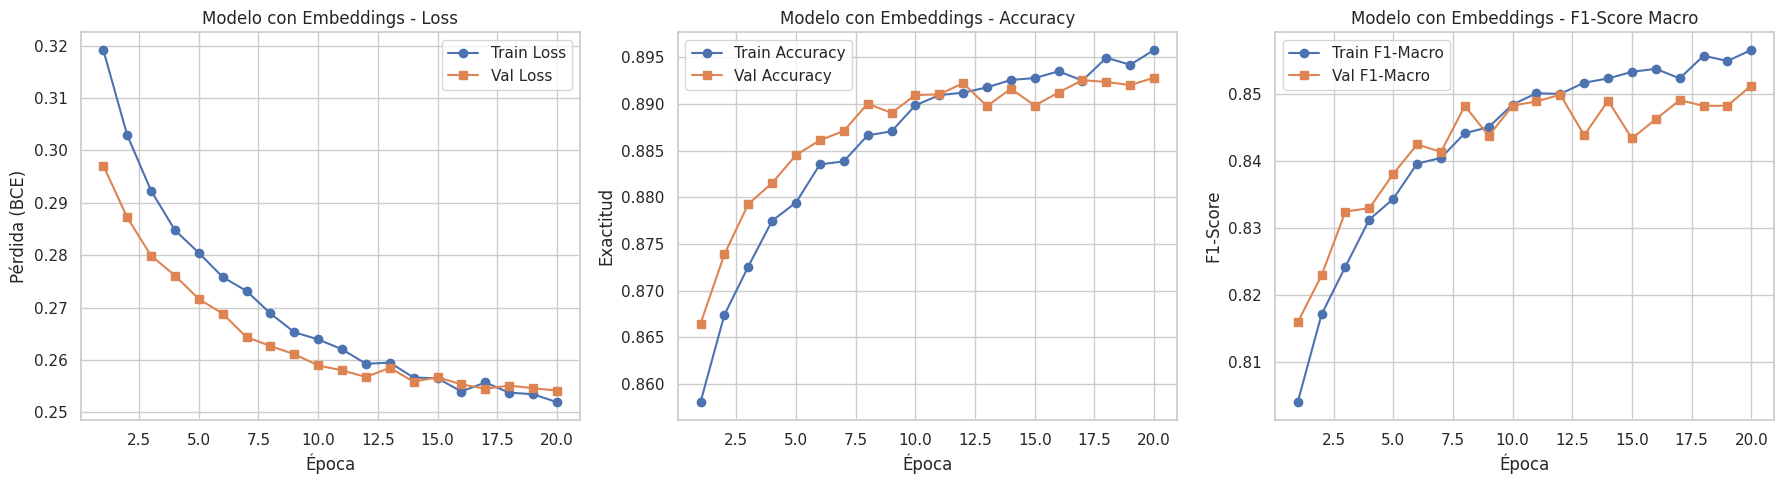

In [ ]:
def plot_learning_curves(history, title_prefix="Modelo con Embeddings"):
    epochs = range(1, len(history['train_loss']) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Loss
    axes[0].plot(epochs, history['train_loss'], label='Train Loss', marker='o')
    axes[0].plot(epochs, history['val_loss'], label='Val Loss', marker='s')
    axes[0].set_title(f'{title_prefix} - Loss')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Pérdida (BCE)')
    axes[0].legend()
    axes[0].grid(True)

    # Accuracy
    axes[1].plot(epochs, history['train_acc'], label='Train Accuracy', marker='o')
    axes[1].plot(epochs, history['val_acc'], label='Val Accuracy', marker='s')
    axes[1].set_title(f'{title_prefix} - Accuracy')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Exactitud')
    axes[1].legend()
    axes[1].grid(True)

    # F1-Score
    axes[2].plot(epochs, history['train_f1'], label='Train F1-Macro', marker='o')
    axes[2].plot(epochs, history['val_f1'], label='Val F1-Macro', marker='s')
    axes[2].set_title(f'{title_prefix} - F1-Score Macro')
    axes[2].set_xlabel('Época')
    axes[2].set_ylabel('F1-Score')
    axes[2].legend()
    axes[2].grid(True)

    plt.tight_layout()
    plt.show()

# Graficar resultados
plot_learning_curves(history_emb)

## c) Diseño y entrenamiento de un modelo sin embeddings (3 puntos)

- Entrenar un segundo modelo, aplicando one-hot encoding a todas las variables que en el punto b) fueron representadas mediante embeddings.
- Quitar todas las capas de dropout, para este segundo modelo no se usará ninguna capa interna de regularización.
- Con respecto al resto de capas, se debe mantener exactamente la misma arquitectura del modelo anterior: igual número de capas, misma cantidad de neuronas por capa y mismas funciones de activación.
- Presentar las mismas métricas, visualizaciones y reportes que en el modelo con embeddings.

In [ ]:
# Se aplica One-Hot Encoding a TODAS las variables categóricas
all_cat_cols = ['sex', 'race', 'relationship', 'marital-status', 'workclass',
                'occupation', 'native-country', 'skill-profile']

ohe_all = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_train_ohe_all = ohe_all.fit_transform(df_train[all_cat_cols])
X_val_ohe_all = ohe_all.transform(df_val[all_cat_cols])

# Concatenar: Numéricas escaladas + Ordinal escalada + OHE completo
X_train_ohe_full = np.hstack([X_train_num, X_train_edu_scaled, X_train_ohe_all]).astype(np.float32)
X_val_ohe_full = np.hstack([X_val_num, X_val_edu_scaled, X_val_ohe_all]).astype(np.float32)

print(f"Dimensión de entrada para el modelo OHE: {X_train_ohe_full.shape[1]}")

# Dataset simple en PyTorch para entrada vectorial única
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset_ohe = TabularDataset(X_train_ohe_full, y_train)
val_dataset_ohe = TabularDataset(X_val_ohe_full, y_val)

train_loader_ohe = DataLoader(train_dataset_ohe, batch_size=128, shuffle=True)
val_loader_ohe = DataLoader(val_dataset_ohe, batch_size=128, shuffle=False)

Dimensión de entrada para el modelo OHE: 159


**Definición del modelo One-Hot encoding**

In [ ]:
class IncomeClassifierOHE(nn.Module):
    def __init__(self, input_dim, dropout_prob=0.3):
        super(IncomeClassifierOHE, self).__init__()

        self.fc1 = nn.Linear(input_dim, 64)
        self.act1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout_prob)

        self.fc2 = nn.Linear(64, 32)
        self.act2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout_prob)

        self.out = nn.Linear(32, 1)

    def forward(self, x):
        x = self.drop1(self.act1(self.fc1(x)))
        x = self.drop2(self.act2(self.fc2(x)))
        return self.out(x)

# Instanciación
input_dim_ohe = X_train_ohe_full.shape[1]
model_ohe = IncomeClassifierOHE(input_dim=input_dim_ohe, dropout_prob=0.3)

**Entrenamiento**

In [ ]:
# Se reutiliza el loop de entrenamiento ajustado para una sola entrada X
def train_and_evaluate_ohe(model, train_loader, val_loader, criterion, optimizer, epochs=20):
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'train_f1': [], 'val_f1': []
    }

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        all_preds_train, all_targets_train = [], []

        for x, y in train_loader:
            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(y)
            preds = (torch.sigmoid(outputs) >= 0.5).float()
            all_preds_train.extend(preds.cpu().numpy())
            all_targets_train.extend(y.cpu().numpy())

        train_loss = running_loss / len(train_loader.dataset)
        train_acc = accuracy_score(all_targets_train, all_preds_train)
        train_f1 = f1_score(all_targets_train, all_preds_train, average='macro')

        model.eval()
        val_running_loss = 0.0
        all_preds_val, all_targets_val = [], []

        with torch.no_grad():
            for x, y in val_loader:
                outputs = model(x)
                loss = criterion(outputs, y)
                val_running_loss += loss.item() * len(y)
                preds = (torch.sigmoid(outputs) >= 0.5).float()
                all_preds_val.extend(preds.cpu().numpy())
                all_targets_val.extend(y.cpu().numpy())

        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = accuracy_score(all_targets_val, all_preds_val)
        val_f1 = f1_score(all_targets_val, all_preds_val, average='macro')

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_f1'].append(train_f1)
        history['val_f1'].append(val_f1)

    return history

criterion_ohe = nn.BCEWithLogitsLoss()
optimizer_ohe = optim.Adam(model_ohe.parameters(), lr=0.001)

history_ohe = train_and_evaluate_ohe(
    model=model_ohe,
    train_loader=train_loader_ohe,
    val_loader=val_loader_ohe,
    criterion=criterion_ohe,
    optimizer=optimizer_ohe,
    epochs=20
)


## d) Conclusiones finales (2 puntos)

- Elaborar una tabla comparativa con los resultados obtenidos por ambos modelos. No solo comparar métricas de precisión, sino también la cantidad final de parámetros y entradas.
- Redactar detalladamente sus observaciones y apreciaciones derivadas de la comparación y plantear conclusiones fundamentadas respecto al desempeño de cada enfoque, justificando por qué uno funciona mejor o peor según las características del problema.

In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

params_emb = count_parameters(model_emb)
params_ohe = count_parameters(model_ohe)

print(f"Parámetros totales - Modelo Embeddings: {params_emb}")
print(f"Parámetros totales - Modelo OHE: {params_ohe}")

Parámetros totales - Modelo Embeddings: 5201
Parámetros totales - Modelo OHE: 12353


In [ ]:
comparison_df = pd.DataFrame({
    'Métrica / Característica': [
        'Dimensión de Entrada',
        'Cantidad Total de Parámetros',
        'Accuracy Validación (Mejor/Último)',
        'F1-Score Macro Validación',
        'Pérdida en Validación (Val Loss)'
    ],
    'Modelo con Embeddings': [
        X_train_dense.shape[1] + sum(dim for _, dim in emb_configs),  # 27 + 11 = 38
        params_emb,
        f"{history_emb['val_acc'][-1]:.4f}",
        f"{history_emb['val_f1'][-1]:.4f}",
        f"{history_emb['val_loss'][-1]:.4f}"
    ],
    'Modelo con One-Hot Encoding': [
        X_train_ohe_full.shape[1],
        params_ohe,
        f"{history_ohe['val_acc'][-1]:.4f}",
        f"{history_ohe['val_f1'][-1]:.4f}",
        f"{history_ohe['val_loss'][-1]:.4f}"
    ]
})

print(comparison_df.to_string(index=False))

          Métrica / Característica Modelo con Embeddings Modelo con One-Hot Encoding
              Dimensión de Entrada                    38                         159
      Cantidad Total de Parámetros                  5201                       12353
Accuracy Validación (Mejor/Último)                0.8928                      0.8913
         F1-Score Macro Validación                0.8513                      0.8470
  Pérdida en Validación (Val Loss)                0.2541                      0.2620


**Análisis cualitativo y conclusiones finales**
1. Eficiencia y reducción de parámetros:
    - Dimensión de entrada: el modelo con One-Hot Encoding (OHE) expande el espacio de características a 159 entradas debido a la alta cardinalidad de variables como skill-profile (80 categorías) y native-country (41 categorías). En cambio, el modelo con Embeddings comprime ese espacio a tan solo 38 entradas densas (27 densas originales/OHE de baja cardinalidad + 11 de los embeddings vectoriales).
    - Cantidad de Parámetros: la reducción en la dimensión de entrada se traduce directamente en una drástica reducción del peso de la red: el modelo con Embeddings utiliza 5.201 parámetros entrenables frente a los 12.353 del modelo OHE (una reducción superior al 57% en la complejidad total de la red).
2. Desempeño predictivo y representación semántica:
    - Métricas de clasificación: a pesar de tener menos de la mitad de parámetros, el modelo con Embeddings supera al modelo tradicional en todas las métricas sobre el conjunto de validación:
    - Accuracy: $+0.15\%$ (0.8928 vs. 0.8913)
    - F1-Score Macro: $+0.43\%$ (0.8513 vs. 0.8470)
    - Pérdida en Validación (Val Loss): Menor error residual (0.2541 vs. 0.2620)
    
La ventaja del F1-Score Macro demuestra que los embeddings ayudan a la red a generalizar mejor en la clase minoritaria (personas con ingresos $>50\text{K}$). OHE asume una equidistancia artificial entre categorías (tratando de forma completamente independiente a dos profesiones o países similares), mientras que las capas de embedding proyectan esas categorías en un espacio vectorial donde el gradiente ajusta distancias continuas, permitiendo capturar patrones semánticos subyacentes entre perfiles laborales y regiones geográficas.

**Conclusión final**

El enfoque basado en Embeddings demuestra ser significativamente más eficiente. logra reducir la dimensionalidad provocada por el One-Hot Encoding en datos de alta cardinalidad, ofreciendo un modelo con menor costo computacional, menor consumo de memoria, mejor capacidad de generalización y un rendimiento predictivo superior.